In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv("project_risk_raw_dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (4000, 51)


,Project_ID,Project_Type,Team_Size,Project_Budget_USD,Estimated_Timeline_Months,Complexity_Score,Stakeholder_Count,Methodology_Used,Team_Experience_Level,Past_Similar_Projects,...,Industry_Volatility,Client_Experience_Level,Change_Control_Maturity,Risk_Management_Maturity,Team_Colocation,Documentation_Quality,Project_Start_Month,Current_Phase_Duration_Months,Seasonal_Risk_Factor,Risk_Level
0,PROJ_0001,Construction,32,1526276.55,32,9.70,16,Waterfall,Senior,3,...,Extreme,First-time,Basic,Basic,Fully Colocated,Good,10,5,1.0,High
1,PROJ_0002,Manufacturing,2,390790.15,9,2.72,9,Kanban,Mixed,0,...,Stable,Occasional,Advanced,Formal,Fully Remote,Poor,9,3,1.0,Low
2,PROJ_0003,Manufacturing,2,246674.76,6,2.04,7,Agile,Mixed,1,...,Stable,Regular,NaN,NaN,Hybrid,Good,5,1,1.0,Medium
3,PROJ_0004,IT,12,1427830.63,17,7.54,16,Scrum,Mixed,0,...,Extreme,Strategic,Formal,Basic,Hybrid,Basic,12,6,1.1,High
4,PROJ_0005,Construction,24,1696746.64,24,6.68,17,Hybrid,Junior,0,...,Moderate,Occasional,Basic,NaN,Partially Colocated,Basic,9,6,1.0,High


In [3]:
df = df.drop(columns=["Project_Type","Methodology_Used","Vendor_Reliability_Score","Communication_Frequency","Regulatory_Compliance_Level","Geographical_Distribution","Integration_Complexity","Organizational_Change_Frequency","Cross_Functional_Dependencies","Technical_Debt_Level","Org_Process_Maturity","Data_Security_Requirements","Key_Stakeholder_Availability","Tech_Environment_Stability","Contract_Type","Industry_Volatility","Change_Control_Maturity", "Team_Colocation","Seasonal_Risk_Factor"])

In [4]:
df.head()

,Project_ID,Team_Size,Project_Budget_USD,Estimated_Timeline_Months,Complexity_Score,Stakeholder_Count,Team_Experience_Level,Past_Similar_Projects,External_Dependencies_Count,Change_Request_Frequency,...,Priority_Level,Previous_Delivery_Success_Rate,Project_Manager_Experience,Resource_Contention_Level,Client_Experience_Level,Risk_Management_Maturity,Documentation_Quality,Project_Start_Month,Current_Phase_Duration_Months,Risk_Level
0,PROJ_0001,32,1526276.55,32,9.70,16,Senior,3,3,1.05,...,Medium,0.80,Mid-level PM,High,First-time,Basic,Good,10,5,High
1,PROJ_0002,2,390790.15,9,2.72,9,Mixed,0,2,2.61,...,Low,0.73,Mid-level PM,Low,Occasional,Formal,Poor,9,3,Low
2,PROJ_0003,2,246674.76,6,2.04,7,Mixed,1,0,0.83,...,High,0.91,Mid-level PM,High,Regular,NaN,Good,5,1,Medium
3,PROJ_0004,12,1427830.63,17,7.54,16,Mixed,0,5,2.42,...,Critical,0.71,Certified PM,High,Strategic,Basic,Basic,12,6,High
4,PROJ_0005,24,1696746.64,24,6.68,17,Junior,0,2,0.16,...,Medium,0.83,Certified PM,High,Occasional,NaN,Basic,9,6,High


In [5]:
null_counts = df.isna().sum().sort_values(ascending=False)
null_counts

Risk_Management_Maturity          791
Project_ID                          0
Project_Budget_USD                  0
Team_Size                           0
Complexity_Score                    0
Stakeholder_Count                   0
Team_Experience_Level               0
Estimated_Timeline_Months           0
External_Dependencies_Count         0
Change_Request_Frequency            0
Project_Phase                       0
Requirement_Stability               0
Team_Turnover_Rate                  0
Historical_Risk_Incidents           0
Technology_Familiarity              0
Past_Similar_Projects               0
Stakeholder_Engagement_Level        0
Schedule_Pressure                   0
Executive_Sponsorship               0
Budget_Utilization_Rate             0
Market_Volatility                   0
Resource_Availability               0
Priority_Level                      0
Funding_Source                      0
Previous_Delivery_Success_Rate      0
Project_Manager_Experience          0
Resource_Con

In [6]:
# Show all columns in DataFrame display
pd.set_option("display.max_columns", None)

df.head()

,Project_ID,Team_Size,Project_Budget_USD,Estimated_Timeline_Months,Complexity_Score,Stakeholder_Count,Team_Experience_Level,Past_Similar_Projects,External_Dependencies_Count,Change_Request_Frequency,Project_Phase,Requirement_Stability,Team_Turnover_Rate,Historical_Risk_Incidents,Technology_Familiarity,Stakeholder_Engagement_Level,Schedule_Pressure,Budget_Utilization_Rate,Executive_Sponsorship,Funding_Source,Market_Volatility,Resource_Availability,Priority_Level,Previous_Delivery_Success_Rate,Project_Manager_Experience,Resource_Contention_Level,Client_Experience_Level,Risk_Management_Maturity,Documentation_Quality,Project_Start_Month,Current_Phase_Duration_Months,Risk_Level
0,PROJ_0001,32,1526276.55,32,9.70,16,Senior,3,3,1.05,Planning,Moderate,0.16,2,Expert,Medium,0.0,0.82,Moderate,Government,0.55,0.98,Medium,0.80,Mid-level PM,High,First-time,Basic,Good,10,5,High
1,PROJ_0002,2,390790.15,9,2.72,9,Mixed,0,2,2.61,Execution,Moderate,0.42,2,Familiar,Excellent,0.0,0.76,Weak,External,0.29,0.95,Low,0.73,Mid-level PM,Low,Occasional,Formal,Poor,9,3,Low
2,PROJ_0003,2,246674.76,6,2.04,7,Mixed,1,0,0.83,Initiation,Stable,0.55,2,Familiar,Excellent,0.0,1.17,Strong,Internal,0.15,0.79,High,0.91,Mid-level PM,High,Regular,NaN,Good,5,1,Medium
3,PROJ_0004,12,1427830.63,17,7.54,16,Mixed,0,5,2.42,Initiation,Moderate,0.33,1,Familiar,Medium,0.1,0.73,Moderate,Mixed,0.74,0.52,Critical,0.71,Certified PM,High,Strategic,Basic,Basic,12,6,High
4,PROJ_0005,24,1696746.64,24,6.68,17,Junior,0,2,0.16,Execution,Stable,0.36,1,Expert,Low,0.0,0.60,Moderate,Government,0.19,0.58,Medium,0.83,Certified PM,High,Occasional,NaN,Basic,9,6,High


In [7]:
# Encode Risk_Level to numeric for correlation
risk_map = {"Low": 1, "Medium": 2, "High": 3, "Critical": 4}
df["Risk_Level_Numeric"] = df["Risk_Level"].map(risk_map)

# Calculate correlation
correlation = df[["Risk_Level_Numeric", "Budget_Utilization_Rate"]].corr()
print("Correlation between Risk Level and Budget Utilization Rate:")
print(correlation)

Correlation between Risk Level and Budget Utilization Rate:
                         Risk_Level_Numeric  Budget_Utilization_Rate
Risk_Level_Numeric                 1.000000                 0.049738
Budget_Utilization_Rate            0.049738                 1.000000


In [8]:
df["Cost_Overrun"] = (df["Budget_Utilization_Rate"] > 1.0).astype(int)


In [9]:
df = df.drop(["Cost_Overrun"], axis=1)

In [10]:
df.drop(columns=["Risk_Level_Numeric","Risk_Level","Project_Manager_Experience", "Client_Experience_Level", "Risk_Management_Maturity", "Documentation_Quality"], inplace=True)

In [11]:
# Show all remaining columns after dropping
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("Remaining columns after dropping:")
print(df.columns.tolist())
print(f"\nTotal columns: {len(df.columns)}")
print(f"Shape: {df.shape}")

Remaining columns after dropping:
['Project_ID', 'Team_Size', 'Project_Budget_USD', 'Estimated_Timeline_Months', 'Complexity_Score', 'Stakeholder_Count', 'Team_Experience_Level', 'Past_Similar_Projects', 'External_Dependencies_Count', 'Change_Request_Frequency', 'Project_Phase', 'Requirement_Stability', 'Team_Turnover_Rate', 'Historical_Risk_Incidents', 'Technology_Familiarity', 'Stakeholder_Engagement_Level', 'Schedule_Pressure', 'Budget_Utilization_Rate', 'Executive_Sponsorship', 'Funding_Source', 'Market_Volatility', 'Resource_Availability', 'Priority_Level', 'Previous_Delivery_Success_Rate', 'Resource_Contention_Level', 'Project_Start_Month', 'Current_Phase_Duration_Months']

Total columns: 27
Shape: (4000, 27)


In [12]:
df = df.drop(columns=["Project_ID"])


In [13]:
print(df.corr(numeric_only=True)["Budget_Utilization_Rate"].sort_values(ascending=False))



Budget_Utilization_Rate           1.000000
Project_Start_Month               0.026590
Past_Similar_Projects             0.013566
Previous_Delivery_Success_Rate    0.011781
Change_Request_Frequency          0.010937
Market_Volatility                 0.009213
Team_Size                         0.006041
Project_Budget_USD               -0.001656
Stakeholder_Count                -0.004783
Current_Phase_Duration_Months    -0.005135
Estimated_Timeline_Months        -0.009104
External_Dependencies_Count      -0.010329
Schedule_Pressure                -0.013285
Resource_Availability            -0.023405
Historical_Risk_Incidents        -0.024057
Complexity_Score                 -0.024203
Team_Turnover_Rate               -0.024518
Name: Budget_Utilization_Rate, dtype: float64


In [14]:
df["Cost_Overrun"] = (df["Budget_Utilization_Rate"] > 1).astype(int)



In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor
import numpy as np



TARGET = "Cost_Overrun"

y = df[TARGET]
X = df.drop(columns=["Budget_Utilization_Rate", "Cost_Overrun"])









In [43]:
cat_cols = X.select_dtypes(include=["object"]).columns
num_cols = X.select_dtypes(include=["number"]).columns

print("Categorical columns:", list(cat_cols))
print("Numeric columns:", list(num_cols))


Categorical columns: ['Team_Experience_Level', 'Project_Phase', 'Technology_Familiarity', 'Priority_Level', 'Resource_Contention_Level']
Numeric columns: ['Team_Size', 'Project_Budget_USD', 'Estimated_Timeline_Months', 'Complexity_Score', 'Stakeholder_Count', 'Past_Similar_Projects', 'External_Dependencies_Count', 'Change_Request_Frequency', 'Historical_Risk_Incidents', 'Schedule_Pressure', 'Market_Volatility', 'Resource_Availability', 'Previous_Delivery_Success_Rate', 'Project_Start_Month', 'Current_Phase_Duration_Months']


In [40]:
df = df.drop(columns=["Requirement_Stability","Team_Turnover_Rate","Stakeholder_Engagement_Level","Funding_Source"])
df = df.drop(columns=["Executive_Sponsorship"])

df.head()

KeyError: "['Requirement_Stability', 'Team_Turnover_Rate', 'Stakeholder_Engagement_Level', 'Funding_Source'] not found in axis"

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [45]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

onehot_cols = ["Team_Experience_Level", "Project_Phase"]

ordinal_cols = [
    "Technology_Familiarity",
    "Priority_Level",
    "Resource_Contention_Level"
]

tech_order = ["New", "Familiar", "Expert"]
priority_order = ["Low", "Medium", "High", "Critical"]
resource_order = ["Low", "Medium", "High"]


In [46]:
preprocess = ColumnTransformer(
    transformers=[
        ("onehot", OneHotEncoder(handle_unknown="ignore"), onehot_cols),
        ("ordinal", OrdinalEncoder(categories=[
            tech_order,
            priority_order,
            resource_order
        ]), ordinal_cols),
    ],
    remainder="passthrough"
)


In [47]:
preprocess.fit(X_train)


c:\Users\DELL\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\compose\_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


ColumnTransformer(remainder='passthrough',
                  transformers=[('onehot',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['Team_Experience_Level', 'Project_Phase']),
                                ('ordinal',
                                 OrdinalEncoder(categories=[['New', 'Familiar',
                                                             'Expert'],
                                                            ['Low', 'Medium',
                                                             'High',
                                                             'Critical'],
                                                            ['Low', 'Medium',
                                                             'High']]),
                                 ['Technology_Familiarity', 'Priority_Level',
                                  'Resource_Contention_Level'])])

In [48]:
X_train_encoded = preprocess.transform(X_train)


In [49]:
X_test_encoded = preprocess.transform(X_test)

In [54]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=2000)

clf.fit(X_train_encoded, y_train)



LogisticRegression(max_iter=2000)

In [55]:
model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("clf", clf)
])

In [56]:
# Predictions
y_pred = clf.predict(X_test_encoded)

# Probabilities
probs = clf.predict_proba(X_test_encoded)[:, 1]


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))



              precision    recall  f1-score   support

           0       0.59      1.00      0.74       472
           1       0.00      0.00      0.00       328

    accuracy                           0.59       800
   macro avg       0.29      0.50      0.37       800
weighted avg       0.35      0.59      0.44       800

Confusion matrix:
 [[472   0]
 [328   0]]
ROC-AUC: 0.496395721372468


c:\Users\DELL\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\DELL\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\DELL\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modif

In [58]:
print("Min probability:", probs.min())
print("Max probability:", probs.max())
print("Mean probability:", probs.mean())


Min probability: 0.34238984186468074
Max probability: 0.47667597833537295
Mean probability: 0.41585210248746846


In [63]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("clf", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_model.fit(X_train, y_train)   # ✅ raw dataframe


c:\Users\DELL\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\compose\_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocess',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Team_Experience_Level',
                                                   'Project_Phase']),
                                                 ('ordinal',
                                                  OrdinalEncoder(categories=[['New',
                                                                              'Familiar',
                                                                              'Expert'],
                                                                             ['Low',
                                                                              'Medium',
                                                                              'High',
                                                                              'Critical'],
                                                                             ['Low',
                                                                              'Medium',
                                                                              'High']]),
                                                  ['Technology_Familiarity',
                                                   'Priority_Level',
                                                   'R...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [65]:
probs = xgb_model.predict_proba(X_test)[:, 1]
print(probs[:10])
print("Minimum probability:", probs.min())
print("Maximum probability:", probs.max())



[0.2939621  0.2284536  0.7394562  0.8678923  0.6753477  0.30445674
 0.5263418  0.49827418 0.32102725 0.12925671]
Minimum probability: 0.015749862
Maximum probability: 0.9429907


Confusion Matrix:
[[321 151]
 [223 105]]


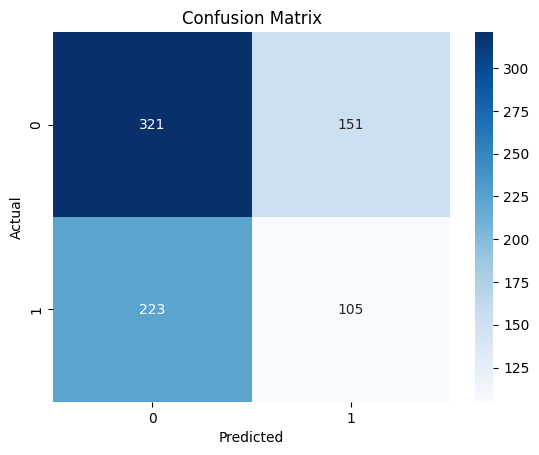

In [67]:
# Get probabilities
probs = xgb_model.predict_proba(X_test)[:, 1]

# Choose threshold
threshold = 0.5

# Convert to binary predictions
y_pred = (probs >= threshold).astype(int)
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


In [68]:
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report

print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Precision: 0.41015625
Recall: 0.3201219512195122
F1-score: 0.3595890410958904
Classification Report:
               precision    recall  f1-score   support

           0       0.59      0.68      0.63       472
           1       0.41      0.32      0.36       328

    accuracy                           0.53       800
   macro avg       0.50      0.50      0.50       800
weighted avg       0.52      0.53      0.52       800

